In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from random import randrange
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import scale
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn import metrics
from sklearn.model_selection import ParameterGrid
from sklearn.cluster import KMeans
import sys
import time
from time import time

#### K-Means for Flow Logs: A Notebook For Threat Hunting Using k-means
Part of the DUNE project (https://github.com/opendr-io/dune) and useful for hunting threats that are resistant to conventional detection or just hunting at great scale. This instance runs k-means on VPC flow logs. Use the silhouette score notebook to compute the best value of k for your dataset first. The output anomalous events can be queried, sifted, aggregated, and sorted using the tools at the end.

In [ ]:
# input file -- the same aggregated flow-log parquet pyod-vflows.ipynb reads (its cell 3)
PARQUET_PATH = "vflowsAgg-637602092272-november-2026.parquet"


In [ ]:
# Read the file. Drop NODATA / SKIPDATA records (log-status), as pyod-vflows does: no
# addresses, ports, protocol or traffic -- every field empty, which would look like an
# extreme value.
pd.set_option("display.max_rows", 5)
pd.set_option("display.max_columns", 30)
kmeans_input = pd.read_parquet(PARQUET_PATH)
if "log-status" in kmeans_input.columns:
    _empty = kmeans_input["log-status"].isin(["NODATA", "SKIPDATA"])
    print(f"dropped {int(_empty.sum()):,} NODATA / SKIPDATA rows, {int((~_empty).sum()):,} left")
    kmeans_input = kmeans_input[~_empty].reset_index(drop=True)

# session_id: the session key joined with "|" -- same format as pyod-vflows' cell 3, so the
# same session gets the same ID in both notebooks and results can be compared. Don't change
# the field order, separator or null handling. Not a feature -- keep it out of CARD_FIELDS.
# e.g. 637602092272|eni-02b85e2a3caf5dd60|52.216.24.124|443|172.16.200.168|46636|6|1583529747|ACCEPT
import pyarrow as pa
import pyarrow.compute as pc

SESSION_KEY = ["account-id", "interface-id", "srcaddr", "srcport", "dstaddr", "dstport",
               "protocol", "start", "action"]
if _miss := [k for k in SESSION_KEY if k not in kmeans_input.columns]:
    raise KeyError(f"can't build session_id -- not in the parquet: {_miss}")
_parts = []
for _k in SESSION_KEY:
    _s = kmeans_input[_k]
    if pd.api.types.is_numeric_dtype(_s) and not pd.api.types.is_bool_dtype(_s):
        _s = _s.astype("Int64")                       # 443, never 443.0
    _parts.append(pc.fill_null(pc.cast(pa.array(_s, from_pandas=True), pa.string()), ""))
kmeans_input["session_id"] = pd.Series(pd.arrays.ArrowStringArray(pc.binary_join_element_wise(*_parts, "|")),
                                       index=kmeans_input.index)
if _nDup := int(kmeans_input["session_id"].duplicated().sum()):
    print(f"!! {_nDup:,} rows share a session_id with another row -- the session key isn't unique in this file")

# un-encoded copy, for pulling the original rows of the anomalies at the end
raw_kmeans = kmeans_input.copy()
print('kmeans_input data shape:')
print(kmeans_input.shape)


dropped 6,682 NODATA / SKIPDATA rows, 3,616,571 left


kmeans_input data shape:
(3616571, 30)


In [ ]:
# Cardinality of the fields listed below -- the same CARD_FIELDS as pyod-vflows (its cell 4)
# and silhouettes-mark-3. Edit the list: comment a line out to skip that field. A name
# kmeans_input doesn't have is reported and skipped. Shows distinct values, share of rows that
# are distinct, nulls, dtype, and a few examples -- sorted by distinct values, highest first.
CARD_FIELDS = [
    "interface-id",
    "protocol",
    "action",
    "tag-direction",
    "tag-country",
    "tag-service"
]

_missing = [c for c in CARD_FIELDS if c not in kmeans_input.columns]
if _missing:
    print(f"!! not in kmeans_input, skipped: {_missing}")
_cf = [c for c in dict.fromkeys(CARD_FIELDS) if c in kmeans_input.columns]

_n = len(kmeans_input)
cardinality = pd.DataFrame({
    "distinct": [kmeans_input[c].nunique(dropna=True) for c in _cf],
    "nulls":    [int(kmeans_input[c].isna().sum()) for c in _cf],
    "dtype":    [str(kmeans_input[c].dtype) for c in _cf],
    "examples": [", ".join(map(str, kmeans_input[c].dropna().unique()[:3])) for c in _cf],
}, index=pd.Index(_cf, name="field"))
cardinality.insert(1, "distinct_pct", cardinality["distinct"] / max(_n, 1))
cardinality = cardinality.sort_values("distinct", ascending=False)

print(f"{_n:,} rows, {len(_cf)} fields")
cardinality.style.format({"distinct": "{:,}", "nulls": "{:,}", "distinct_pct": "{:.2%}"})


3,616,571 rows, 6 fields


,distinct,distinct_pct,nulls,dtype,examples
field,,,,,
tag-country,220,0.01%,10,string,"United States, Seychelles, China"
tag-service,41,0.00%,"2,200,941",string,"HTTPS, SMB, SSH"
interface-id,12,0.00%,0,object,"eni-02b85e2a3caf5dd60, eni-0f324b6f6044e4ef3, eni-0a98cf7cabe3677e3"
protocol,7,0.00%,0,Int64,"6, 17, 1"
tag-direction,2,0.00%,0,string,"north-south, east-west"
action,2,0.00%,0,object,"ACCEPT, REJECT"


In [ ]:
# Select fields to encode: CARD_FIELDS from the cell above (names kmeans_input doesn't have
# are left out), as pyod-vflows' cell 5 does. Warns about any field with more than
# MAX_CARDINALITY distinct values -- as category codes, high-cardinality fields (addresses,
# ports, timestamps) give arbitrary numbers that k-means treats as distances.
kmeans_fields_to_encode = [c for c in CARD_FIELDS if c in kmeans_input.columns]
print(f"{len(kmeans_fields_to_encode)} fields: {', '.join(kmeans_fields_to_encode)}")

MAX_CARDINALITY = 1000
_hiCard = {c: n for c in kmeans_fields_to_encode if (n := kmeans_input[c].nunique()) > MAX_CARDINALITY}
for _c, _n in sorted(_hiCard.items(), key=lambda kv: -kv[1]):
    print(f"!! {_c}: {_n:,} distinct values (> {MAX_CARDINALITY:,})")


6 fields: interface-id, protocol, action, tag-direction, tag-country, tag-service


In [ ]:
# Select the columns you want to use for outlier detection -- a copy of
# kmeans_fields_to_encode, so editing one list doesn't change the other.
kmeans_columns_for_outliers = list(kmeans_fields_to_encode)


In [ ]:
# K: number of clusters, read from silhouette_k.json -- silhouettes-mark-3 writes it after its
# silhouette search. Used only when it was computed on the same parquet and fields as this
# notebook (PARQUET_PATH, kmeans_columns_for_outliers); otherwise K_FALLBACK, with the reason.
# K_OVERRIDE = a number uses that instead, whatever the file says.
import json, os
SILHOUETTE_K_FILE = "silhouette_k.json"
K_FALLBACK = 12
K_OVERRIDE = None

def _read_k():
    if K_OVERRIDE is not None:
        return int(K_OVERRIDE), "K_OVERRIDE"
    if not os.path.exists(SILHOUETTE_K_FILE):
        return K_FALLBACK, f"K_FALLBACK -- no {SILHOUETTE_K_FILE}; run silhouettes-mark-3 first"
    with open(SILHOUETTE_K_FILE, encoding="utf-8") as f:
        s = json.load(f)
    if s.get("parquet") != PARQUET_PATH:
        return K_FALLBACK, f"K_FALLBACK -- {SILHOUETTE_K_FILE} is for {s.get('parquet')}, not {PARQUET_PATH}"
    if s.get("fields") != list(kmeans_columns_for_outliers):
        return K_FALLBACK, (f"K_FALLBACK -- {SILHOUETTE_K_FILE} is for fields {s.get('fields')}, "
                            f"not {list(kmeans_columns_for_outliers)}")
    return int(s["k"]), (f"{SILHOUETTE_K_FILE} (score {s['score']:.3f}, computed {s['computed']}, "
                         + ("on distinct combinations)" if s.get("distinct") else "on every session)"))

K, _kFrom = _read_k()
print(f"K = {K}, from {_kFrom}")


K = 2, from silhouette_k.json (score 0.532, computed 2026-11-09T16:46:58, on distinct combinations)


In [ ]:
kmeans_input.dtypes

start                    Int64
end                      Int64
                    ...       
tag-service     string[python]
session_id     string[pyarrow]
Length: 30, dtype: object

In [ ]:
# sum uniuque field values, can inform pre-processing decisions
sum_n_unique = 0
for field in kmeans_fields_to_encode:
    print(field)
    print(kmeans_input[field].nunique())
    sum_n_unique += kmeans_input[field].nunique()
    print(kmeans_input[field].value_counts())
    print("==============")

interface-id


12


interface-id
eni-02b85e2a3caf5dd60    1892358
eni-0f324b6f6044e4ef3     766857
                          ...   
eni-08af5ded4adefd40f        140
eni-03066304b96ceb901         15
Name: count, Length: 12, dtype: int64
protocol
7
protocol
6      3284633
17      318034
        ...   
132          3
4            2
Name: count, Length: 7, dtype: Int64
action


2


action
REJECT    2552261
ACCEPT    1064310
Name: count, dtype: int64
tag-direction
2


tag-direction
north-south    3616561
east-west           10
Name: count, dtype: Int64
tag-country
220


tag-country
United States    1315980
Russia            354634
                  ...   
Palau                  1
Nauru                  1
Name: count, Length: 220, dtype: Int64
tag-service
41


tag-service
HTTPS                 466764
SSH                   456005
                       ...  
SCTP                       3
IP-in-IP Tunneling         2
Name: count, Length: 41, dtype: Int64


In [ ]:
print(sum_n_unique)

284


In [ ]:
# print statistical summary, useful in assesing balance 
for field in kmeans_fields_to_encode:
    print(field)
    print(kmeans_input[field].value_counts().describe())
    print("==============")

interface-id


count    1.200000e+01
mean     3.013809e+05
             ...     
75%      2.928768e+05
max      1.892358e+06
Name: count, Length: 8, dtype: float64
protocol
count          7.0
mean      516653.0
           ...    
75%       165626.0
max      3284633.0
Name: count, Length: 8, dtype: Float64
action


count          2.00
mean     1808285.50
            ...    
75%      2180273.25
max      2552261.00
Name: count, Length: 8, dtype: float64
tag-direction


count           2.0
mean      1808285.5
            ...    
75%      2712423.25
max       3616561.0
Name: count, Length: 8, dtype: Float64
tag-country


count           220.0
mean     16438.913636
             ...     
75%            1517.0
max         1315980.0
Name: count, Length: 8, dtype: Float64
tag-service


count            41.0
mean     34527.560976
             ...     
75%           10757.0
max          466764.0
Name: count, Length: 8, dtype: Float64


In [ ]:
#convert to categorical type and then to integers 
for field in kmeans_fields_to_encode:
    kmeans_input[field] = kmeans_input[field].astype('category')
    kmeans_input[field] = kmeans_input[field].cat.codes

In [ ]:
print(kmeans_input.columns)

Index(['start', 'end', 'version', 'account-id', 'interface-id', 'srcaddr',
       'src-int', 'dstaddr', 'dst-int', 'srcport', 'dstport', 'protocol',
       'packets', 'bytes', 'action', 'log-status', 'start_time', 'end_time',
       'records', 'tag-src-public', 'tag-dst-public', 'tag-direction',
       'tag-org', 'tag-cloud', 'tag-asn', 'tag-cc', 'tag-country', 'conflict',
       'tag-service', 'session_id'],
      dtype='object')


#### Apply PCA for dimensionality reduction


In [14]:
#remove the mean and scale each feature/variable to unit variance
KX = kmeans_input.loc[:, kmeans_columns_for_outliers].values
# Standardizing the features
KX = StandardScaler().fit_transform(KX)

In [15]:
print(np.asarray(KX).shape, np.asarray(KX).dtype)


(3616571, 6) float64


In [16]:
kmeans_pca_2 = PCA(n_components=2)
KX2 = kmeans_pca_2.fit_transform(KX)
#reduce dimensionality of the data so we can plot it
print(KX2.shape)
print(np.asarray(KX).shape, np.asarray(KX).dtype)

(3616571, 2)
(3616571, 6) float64


In [17]:
from time import perf_counter
from sklearn.decomposition import PCA

print("before PCA", KX.shape, KX.dtype, flush=True)

t0 = perf_counter()
pca_5 = PCA(n_components=min(5, KX.shape[1]))   # no more components than fields
KX = pca_5.fit_transform(KX)
print("after PCA", KX.shape, "secs:", perf_counter() - t0, flush=True)


before PCA (3616571, 6) float64


after PCA (3616571, 5) secs: 0.44059899999410845


In [18]:
# variable to represent a fraction of the data considered to be outliers 
kmeans_num_samples = kmeans_input.shape[0]
kmeans_out_frac=0.01

In [19]:
kmeans_fraction_of_inliers = (1. - kmeans_out_frac) 
# (1 - fraction of outliers)
kmeans_num_inliers = int(kmeans_fraction_of_inliers * kmeans_num_samples)
# fraction of inliers * total number of samples
kmeans_num_outliers = int(kmeans_out_frac * kmeans_num_samples) 
# fraction of outliers * total number of samples

In [20]:
print('No. of inliers: %i' % kmeans_num_inliers)
print('No. of outliers: %i' % kmeans_num_outliers)

No. of inliers: 3580405
No. of outliers: 36165


In [21]:
random_state_number = 42
rs = np.random.RandomState(random_state_number)  
# random state - force the centroids to begin 
# in the same locations bc we are going to compare 
# different clusters 
print(type(KX2))

<class 'numpy.ndarray'>


In [22]:
import numpy as np
import time
from sklearn.cluster import KMeans, MiniBatchKMeans

n_full = len(KX2)

def time_fit(model, X):
    t0 = time.perf_counter()
    model.fit(X)
    return time.perf_counter() - t0

def quick_forecast(make_model, X, sizes=(2000, 5000), seed=42):
    rng = np.random.default_rng(seed)
    results = []
    n = len(X)
    for s in sizes:
        s = min(s, n)
        if s < 50:
            continue
        idx = rng.choice(n, size=s, replace=False)
        t = time_fit(make_model(), X[idx])
        results.append((s, t))
    if len(results) < 2:
        return None, results
    (n1, t1), (n2, t2) = results
    b = np.log(t2 / t1) / np.log(n2 / n1)
    a = t1 / (n1 ** b)
    t_pred = a * (n_full ** b)
    return t_pred, results

candidates = {
    "default": lambda: KMeans(n_clusters=K, random_state=42),
    "safe": lambda: KMeans(
        n_clusters=K, init="k-means++", n_init=3, max_iter=100,
        algorithm="elkan", random_state=42
    ),
    "minibatch": lambda: MiniBatchKMeans(
        n_clusters=K, batch_size=2048, n_init=3, max_iter=100, random_state=42
    ),
}

for name, make_model in candidates.items():
    t_pred, samples = quick_forecast(make_model, KX2)
    if t_pred is None:
        print(f"{name}: not enough data to forecast, samples={samples}")
    else:
        print(f"{name}: samples={samples} | predicted runtime={t_pred:.2f}s")

print("Set kmeans_mode to 'default', 'safe', or 'minibatch' in the next cell.")


default: samples=[(2000, 3.76601419999497), (5000, 0.00411040000471985)] | predicted runtime=0.00s
safe: samples=[(2000, 0.005622000004223082), (5000, 0.012474000002839603)] | predicted runtime=3.83s
minibatch: samples=[(2000, 0.007699599998886697), (5000, 0.008838800000376068)] | predicted runtime=0.02s
Set kmeans_mode to 'default', 'safe', or 'minibatch' in the next cell.


In [23]:
kmeans_mode = "default"  # change to 'safe' or 'minibatch'

kmeans = candidates[kmeans_mode]()
t0 = time.perf_counter()
kmeans.fit(KX2)
print(f"{kmeans_mode} runtime: {time.perf_counter() - t0:.2f}s")


default runtime: 1.09s


In [24]:
center = kmeans.cluster_centers_
print(center)
# output the centroids

[[-1.83695348  0.0339781 ]
 [ 0.88835463 -0.01643188]]


In [25]:
PERCENTILE=99.0

In [26]:
# Predict the closest cluster for each data point
closest_cluster = kmeans.predict(KX2)
kmeans_input['cluster'] = kmeans.predict(KX2)

# Calculate the distance of each data point to its closest cluster center
distances = pairwise_distances_argmin_min(KX2, kmeans.cluster_centers_)[1]

# Define a threshold to identify anomalies
threshold = np.percentile(distances, PERCENTILE)

# Find the indices of the anomalies
kmeans_anomaly_indices = np.where(distances > threshold)[0]

# Print the indices of the anomalies
print("Anomaly indices:", kmeans_anomaly_indices)
print(len(kmeans_anomaly_indices))

Anomaly indices: [    141     344     372 ... 3616395 3616405 3616509]
32382


In [27]:
# add two columns: cluster (the closest cluster of each row) and outlier_kmeans (1 for the
# rows past the distance threshold, else 0). Vectorized -- a row-by-row loop takes hours on
# millions of sessions.
kmeans_input['cluster'] = closest_cluster
_out = np.zeros(len(kmeans_input), dtype=int)
_out[kmeans_anomaly_indices] = 1
kmeans_input['outlier_kmeans'] = _out


In [28]:
#create two new columns, c1 and c2, and populate them with values from a 2D array
kmeans_input[['c1', 'c2']] = KX[:, :2]

In [29]:
print(len(kmeans_input.query('outlier_kmeans == 1')))
#count the number of outliers

32382


In [30]:
print(closest_cluster)

[0 0 0 ... 0 0 1]


In [31]:
kmeans_input.columns

Index(['start', 'end', 'version', 'account-id', 'interface-id', 'srcaddr',
       'src-int', 'dstaddr', 'dst-int', 'srcport', 'dstport', 'protocol',
       'packets', 'bytes', 'action', 'log-status', 'start_time', 'end_time',
       'records', 'tag-src-public', 'tag-dst-public', 'tag-direction',
       'tag-org', 'tag-cloud', 'tag-asn', 'tag-cc', 'tag-country', 'conflict',
       'tag-service', 'session_id', 'cluster', 'outlier_kmeans', 'c1', 'c2'],
      dtype='object')

In [32]:
print(KX2)

[[-1.40098493  0.00779831]
 [-1.40098493  0.00779831]
 [-1.40098493  0.00779831]
 ...
 [-1.2023581   0.19777111]
 [-1.2023581   0.19777111]
 [ 0.62871637  0.2123476 ]]


In [33]:
print(len(KX2))

3616571


In [34]:
print(kmeans_input.shape)

(3616571, 34)


In [35]:
# create new series by selecting values from the columns at the positions 
# specified in kmeans_anomaly_indices. This series will contain the c1 values of the 
# data points that are considered anomalies.
x_anom = kmeans_input['c1'][kmeans_anomaly_indices]
y_anom = kmeans_input['c2'][kmeans_anomaly_indices]

In [36]:
# new version of the above cell - maybe unncesessay 

idx = np.asarray(kmeans_anomaly_indices).ravel()

assert idx.ndim == 1
assert idx.max() < len(kmeans_input)

x_anom = kmeans_input['c1'].to_numpy()[idx]
y_anom = kmeans_input['c2'].to_numpy()[idx]


In [37]:
sns.set(rc={"figure.figsize":(15, 10)}) #width=15, #height=10

D:\.venv\Lib\site-packages\IPython\core\events.py:96: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


D:\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


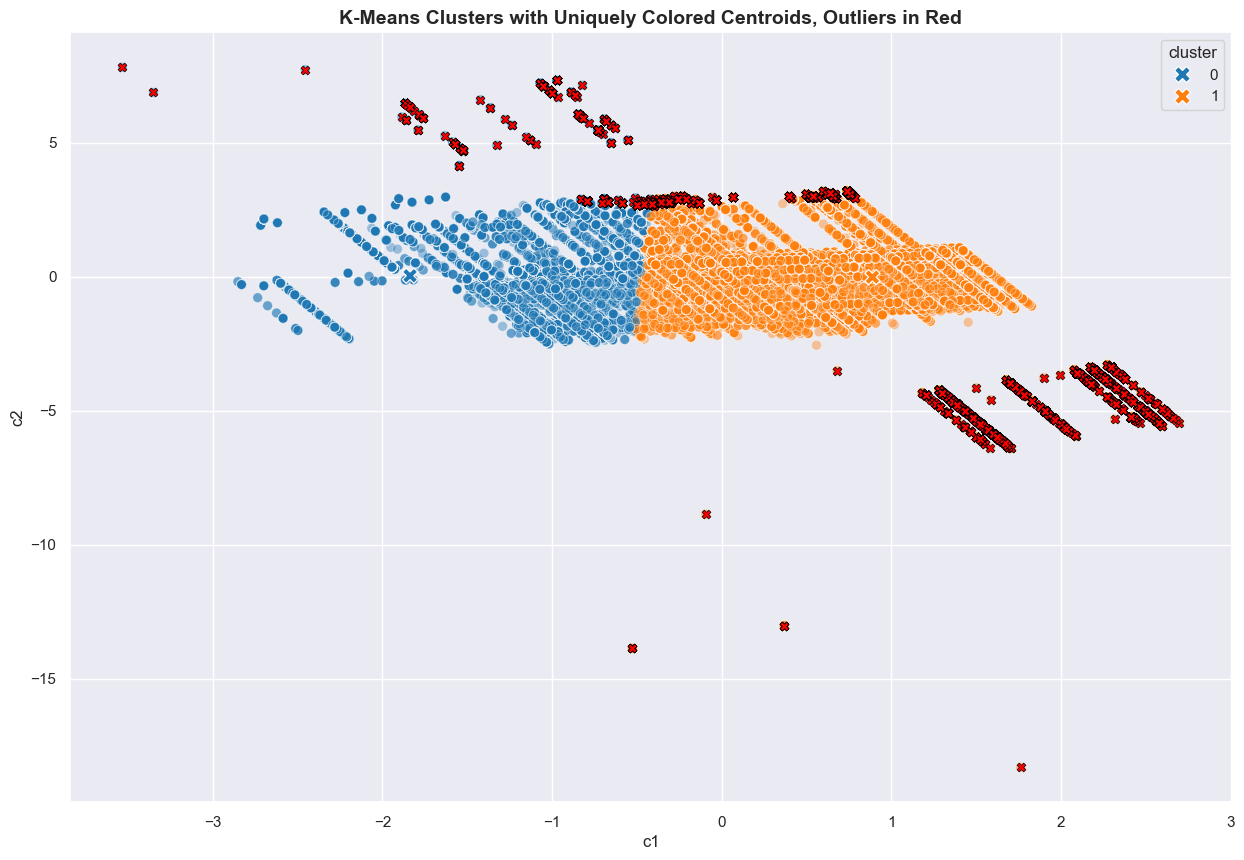

In [38]:
# pd.plotting.parallel_coordinates(KX2, 'cluster')
# KX -- cluster center
# s (square) = outlier
# use Seaborn's scatterplot function to plot the c1 and c2 columns
# from DataFrame kmeans_input. The hue parameter is set to kmeans.labels_, 
# which are the labels assigned by a k-means clustering algorithm, 
# thereby coloring each point according to its cluster label.

ax = sns.scatterplot(
    x=kmeans_input['c1'],
    y=kmeans_input['c2'],
    hue=kmeans.labels_,
    palette='tab10',     # or tab20 if K > 10
    alpha=0.4,
    s=50,
    legend=False        # important: avoid legend overload
)

# plot the centers of the clusters. The centers are accessed via kmeans.cluster_centers_,
# and hue=range(K) assigns a unique color to each center. The centers are plotted 
# with a larger size (s=80) and a different marker style (marker='KX')
centers_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=['c1', 'c2']
)
centers_df['cluster'] = centers_df.index.astype(str)

sns.scatterplot(
    data=centers_df,
    x='c1',
    y='c2',
    hue='cluster',
    palette='tab10',   # or 'tab20' if K > 10
    marker='X',
    s=120,
    legend='full',
    ax=ax
)
# Anomalies are plotted with distinctive styling to make them stand out: 
# red color, square markers (marker='s'), larger size (s=40), and 
# a black edge (edgecolor='black').
sns.scatterplot(
    x=x_anom,
    y=y_anom,
    color="red",
    s=40,
    marker="X",
    edgecolor="black",
    legend=False,
    ax=ax
)
ax.set_title(
    "K-Means Clusters with Uniquely Colored Centroids, Outliers in Red",
    fontsize=14,
    fontweight="bold"
);

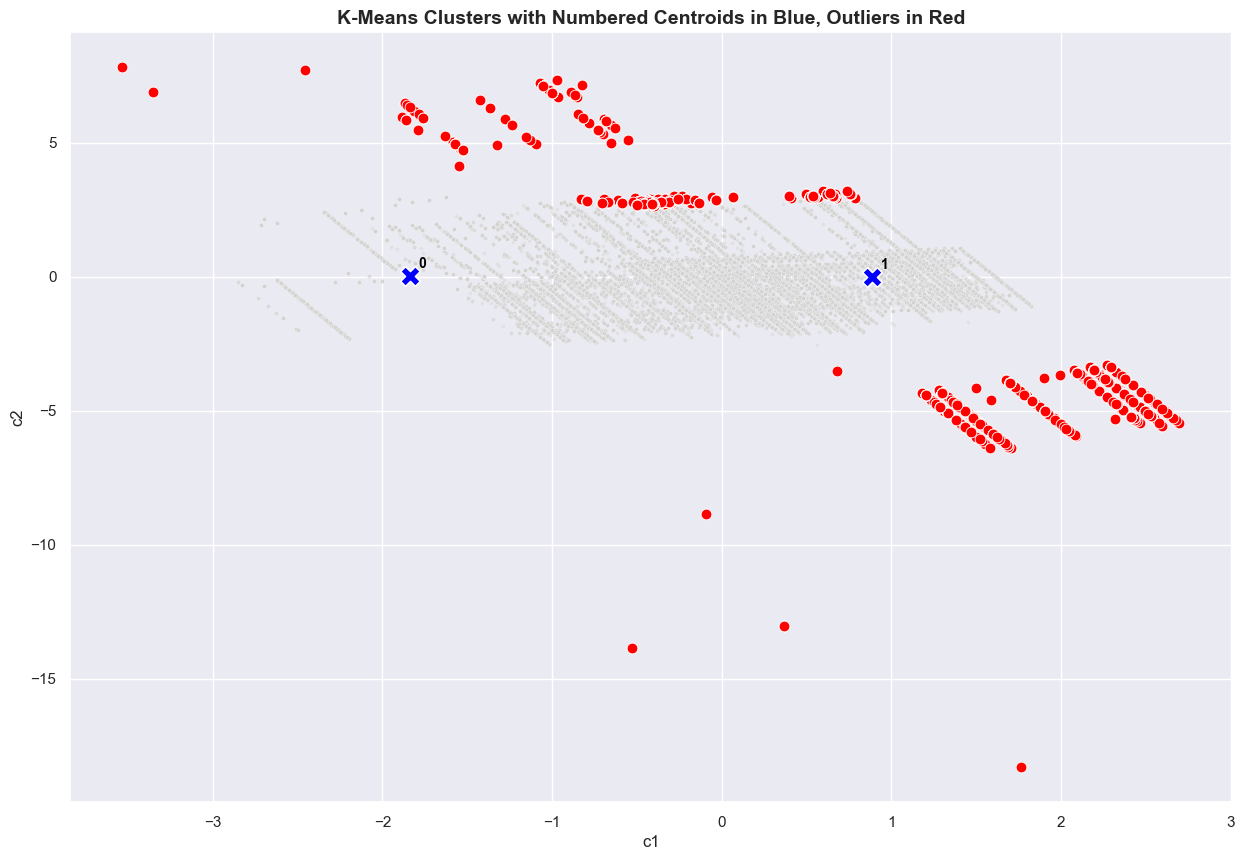

In [39]:
# alternative plot with numbered centers - may be more readable
# than a conventional legend with a lot of centers

ax = sns.scatterplot(
    x=kmeans_input['c1'],
    y=kmeans_input['c2'],
    color="lightgray",
    alpha=0.4,
    s=10
)
# Plot cluster centers
sns.scatterplot(
    x=kmeans.cluster_centers_[:, 0],
    y=kmeans.cluster_centers_[:, 1],
    color="blue",
    marker="X",
    s=200,
    ax=ax
)
sns.scatterplot(
    x=kmeans_input.loc[idx, 'c1'],
    y=kmeans_input.loc[idx, 'c2'],
    color="red",
    s=60,
    ax=ax
)
# Number the centers
for i, (cx, cy) in enumerate(kmeans.cluster_centers_):
    ax.annotate(
        str(i),
        (cx, cy),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="black"
    )
ax.set_title(
    "K-Means Clusters with Numbered Centroids in Blue, Outliers in Red",
    fontsize=14,
    fontweight="bold"
)
plt.show()

In [40]:
# Normalize outlier_kmeans: force numeric 0/1, anything else -> NaN
kmeans_input['outlier_kmeans'] = pd.to_numeric(kmeans_input['outlier_kmeans'], errors='coerce')

print("dtype after numeric coercion:", kmeans_input['outlier_kmeans'].dtype)
print(kmeans_input['outlier_kmeans'].value_counts(dropna=False))

dtype after numeric coercion: int64
outlier_kmeans
0    3584189
1      32382
Name: count, dtype: int64


In [41]:
# scored anomalies: the original (un-encoded) rows k-means flagged, from raw_kmeans (the copy
# made when loading), joined on session_id, with outlier_kmeans and cluster attached
kmeans_anomalies_scored = kmeans_input.loc[kmeans_input['outlier_kmeans'] == 1,
                                           ['session_id', 'outlier_kmeans', 'cluster']].copy()

# session_ids that were flagged
kmeans_anomalous_ids = kmeans_anomalies_scored['session_id'].unique()

kmeans_output = raw_kmeans[raw_kmeans['session_id'].isin(kmeans_anomalous_ids)].copy()
kmeans_output = kmeans_output.merge(
    kmeans_anomalies_scored,
    on='session_id',
    how='left',
    suffixes=('', '_score')
)
print(f"{len(kmeans_output):,} anomalous sessions")
pd.set_option('display.max_rows', 5)
pd.set_option('display.max_colwidth', None)
kmeans_output


32,382 anomalous sessions


,start,end,version,account-id,interface-id,srcaddr,src-int,dstaddr,dst-int,srcport,dstport,protocol,packets,bytes,action,...,end_time,records,tag-src-public,tag-dst-public,tag-direction,tag-org,tag-cloud,tag-asn,tag-cc,tag-country,conflict,tag-service,session_id,outlier_kmeans,cluster
0,1583525220,1583525272,2,637602092272,eni-0f324b6f6044e4ef3,209.17.96.58,3507576890,172.16.200.145,2886781073,62068,17185,17,1.0,92.0,REJECT,...,2020-03-06 20:07:52+00:00,1,True,False,north-south,<NA>,<NA>,"COGENT-174 - Cogent Communications, LLC",US,United States,False,<NA>,637602092272|eni-0f324b6f6044e4ef3|209.17.96.58|62068|172.16.200.145|17185|17|1583525220|REJECT,1,1
1,1583526026,1583526086,2,637602092272,eni-02b85e2a3caf5dd60,209.17.96.42,3507576874,172.16.200.168,2886781096,0,0,1,1.0,40.0,REJECT,...,2020-03-06 20:21:26+00:00,1,True,False,north-south,<NA>,<NA>,"COGENT-174 - Cogent Communications, LLC",US,United States,False,ICMP,637602092272|eni-02b85e2a3caf5dd60|209.17.96.42|0|172.16.200.168|0|1|1583526026|REJECT,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32380,1660677530,1660677581,2,637602092272,eni-03589d9be46b47132,222.78.136.211,3729688787,172.16.200.140,2886781068,0,0,47,1.0,564.0,REJECT,...,2022-08-16 19:19:41+00:00,1,True,False,north-south,<NA>,<NA>,"CHINANET-BACKBONE - No.31,Jin-rong Street",CN,China,False,GRE,637602092272|eni-03589d9be46b47132|222.78.136.211|0|172.16.200.140|0|47|1660677530|REJECT,1,0
32381,1660677883,1660677941,2,637602092272,eni-03589d9be46b47132,86.106.90.59,1449810491,172.16.200.140,2886781068,0,0,1,1.0,36.0,REJECT,...,2022-08-16 19:25:41+00:00,1,True,False,north-south,<NA>,<NA>,M247 M247 Europe SRL,RO,Romania,False,ICMP,637602092272|eni-03589d9be46b47132|86.106.90.59|0|172.16.200.140|0|1|1660677883|REJECT,1,1


In [42]:
# check the join: each flagged session_id found in raw_kmeans, and its start_time matches
kmeans_ts_check = (
    raw_kmeans[['session_id', 'start_time']]
    .merge(
        kmeans_output[['session_id', 'start_time']],
        on='session_id',
        how='inner',
        suffixes=('_raw_kmeans', '_kmeans_output')
    )
)

# compare timestamps
kmeans_ts_check['session_id_match'] = (
    kmeans_ts_check['start_time_raw_kmeans'] == kmeans_ts_check['start_time_kmeans_output']
)

# count matches
kmeans_tmatch_counts = kmeans_ts_check['session_id_match'].value_counts()

num_correct = kmeans_tmatch_counts.get(True, 0)
num_incorrect = kmeans_tmatch_counts.get(False, 0)

print(f"Timestamp matches   : {num_correct}")
print(f"Timestamp mismatches: {num_incorrect}")
print(f"Total compared      : {num_correct + num_incorrect}")

# sanity check (optional)
if num_incorrect > 0:
    print("WARNING: There are mismatched timestamps")

# we are done with raw_kmeans — free memory
#del raw_kmeans
#print('deleted the raw_kmeans dataframe to free memory.')


Timestamp matches   : 32382
Timestamp mismatches: 0
Total compared      : 32382


In [43]:
# write kmeans_output to the output folder as parquet and CSV, named after the AWS account and
# today's date, e.g. output/kmeans-output-637602092272-november-10-2026.parquet (and .csv).
# Adds a "type" field first, saying which detection made the rows (as flows-dbscan's
# dbscan_output). The account comes from the account-id of the loaded sessions (raw_kmeans);
# several accounts are joined with "+". OUT_DIR is the folder, created if it isn't there.
import os

OUT_DIR     = "output"
KMEANS_TYPE = "kmeans anomaly detection"

if "type" in kmeans_output.columns:
    kmeans_output = kmeans_output.drop(columns="type")
kmeans_output.insert(0, "type", KMEANS_TYPE)

if "account-id" not in raw_kmeans.columns:
    raise KeyError("raw_kmeans has no 'account-id' column -- can't name the file")
_accts = sorted(raw_kmeans["account-id"].dropna().astype(str).str.strip().unique())
_accts = [a for a in _accts if a and a != "-"]
if not _accts:
    raise ValueError("no account-id values in raw_kmeans -- can't name the file")
_now  = pd.Timestamp.now()
_base = os.path.join(OUT_DIR, f"kmeans-output-{'+'.join(_accts)}-"
                              f"{_now.strftime('%B').lower()}-{_now.day}-{_now.year}")
os.makedirs(OUT_DIR, exist_ok=True)
KMEANS_OUT_PARQUET = _base + ".parquet"
KMEANS_OUT_CSV     = _base + ".csv"
kmeans_output.to_parquet(KMEANS_OUT_PARQUET, index=False)
kmeans_output.to_csv(KMEANS_OUT_CSV, index=False)
print(f"wrote {len(kmeans_output):,} rows, {kmeans_output.shape[1]} columns to")
print(f"  {KMEANS_OUT_PARQUET}")
print(f"  {KMEANS_OUT_CSV}")


wrote 32,382 rows, 33 columns to
  output\kmeans-output-637602092272-november-10-2026.parquet
  output\kmeans-output-637602092272-november-10-2026.csv


In [44]:
from threadpoolctl import threadpool_info
threadpool_info()


[{'user_api': 'blas',
  'internal_api': 'openblas',
  'num_threads': 4,
  'prefix': 'libscipy_openblas',
  'filepath': 'D:\\.venv\\Lib\\site-packages\\numpy.libs\\libscipy_openblas64_-9e3e5a4229c1ca39f10dc82bba9e2b2b.dll',
  'version': '0.3.30',
  'threading_layer': 'pthreads',
  'architecture': 'SkylakeX'},
 {'user_api': 'blas',
  'internal_api': 'openblas',
  'num_threads': 4,
  'prefix': 'libscipy_openblas',
  'filepath': 'D:\\.venv\\Lib\\site-packages\\scipy.libs\\libscipy_openblas-64eda39e79589aedb16f58e5547eb599.dll',
  'version': '0.3.30',
  'threading_layer': 'pthreads',
  'architecture': 'SkylakeX'},
 {'user_api': 'openmp',
  'internal_api': 'openmp',
  'num_threads': 4,
  'prefix': 'vcomp',
  'filepath': 'D:\\.venv\\Lib\\site-packages\\sklearn\\.libs\\vcomp140.dll',
  'version': None}]

In [45]:
import time
from sklearn.cluster import KMeans

t0 = time.perf_counter()
kmeans = KMeans(n_clusters=K, random_state=42).fit(KX2)
print(f"Actual runtime: {time.perf_counter() - t0:.2f}s")


Actual runtime: 0.95s
